In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeRegressor
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.metrics import root_mean_squared_error, r2_score
from sklearn.pipeline import Pipeline

In [2]:
FILE_PATH = 'UsedCars.csv'
data = pd.read_csv(FILE_PATH)

In [3]:
data.head()

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
0,11,97064.0,NaN,77,Hyundai,hybrid,manual,no,3805
1,10,74340.0,NaN,135,BMW,petrol,automatic,no,4851
2,6,69312.0,1.4,95,Toyota,petrol,NaN,no,5379
3,8,126280.0,NaN,89,Kia,hybrid,automatic,no,5471
4,2,42026.0,1.4,98,BMW,hybrid,automatic,no,6740


In [4]:
data.tail()

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
295,8,103080.0,3.0,206,BMW,petrol,manual,no,49793
296,3,27051.0,NaN,98,BMW,hybrid,automatic,no,50132
297,1,18300.0,1.2,67,Kia,diesel,manual,no,51006
298,11,170764.0,1.6,90,BMW,petrol,manual,no,51169
299,5,103115.0,2.0,141,BMW,diesel,manual,no,51396


In [5]:
data.sample(3)

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history,price_azn
73,2,42644.0,3.0,181,BMW,petrol,manual,yes,21847
231,6,133806.0,1.6,120,BMW,NaN,manual,yes,35074
258,8,127056.0,NaN,105,Toyota,petrol,manual,no,38680


In [6]:
data.shape

(300, 9)

In [7]:
data.dtypes

age_years             int64
mileage_km          float64
engine_l            float64
power_hp              int64
brand                   str
fuel_type               str
transmission            str
accident_history        str
price_azn             int64
dtype: object

In [8]:
data.isna().sum()

age_years            0
mileage_km          17
engine_l            16
power_hp             0
brand                0
fuel_type           13
transmission        10
accident_history     0
price_azn            0
dtype: int64

In [9]:
data.describe()

,age_years,mileage_km,engine_l,power_hp,price_azn
count,300.000000,283.000000,284.000000,300.000000,300.000000
mean,7.850000,118302.176678,1.901761,123.270000,27806.573333
std,4.147066,73652.009931,0.581484,39.903861,9772.778467
min,1.000000,8659.000000,1.200000,57.000000,3805.000000
25%,4.000000,54862.500000,1.400000,93.000000,21865.500000
50%,8.000000,112308.000000,1.800000,113.000000,27458.500000
75%,11.000000,166869.500000,2.500000,151.250000,34844.750000
max,15.000000,334305.000000,3.000000,218.000000,51396.000000


In [10]:
target_col = 'price_azn'
y = data[target_col].values
X = data.drop(columns=[target_col])

In [11]:
X.head()

,age_years,mileage_km,engine_l,power_hp,brand,fuel_type,transmission,accident_history
0,11,97064.0,NaN,77,Hyundai,hybrid,manual,no
1,10,74340.0,NaN,135,BMW,petrol,automatic,no
2,6,69312.0,1.4,95,Toyota,petrol,NaN,no
3,8,126280.0,NaN,89,Kia,hybrid,automatic,no
4,2,42026.0,1.4,98,BMW,hybrid,automatic,no


In [12]:
y

array([ 3805,  4851,  5379,  5471,  6740,  7922,  9250,  9778,  9858,
       10011, 10022, 10279, 10408, 10615, 11050, 11245, 11548, 11915,
       12222, 12444, 12492, 12811, 12844, 12952, 12969, 12971, 13371,
       13376, 13707, 14167, 15045, 15071, 15121, 15314, 15416, 15549,
       15639, 16049, 16091, 16392, 16818, 16950, 17153, 17531, 17595,
       17736, 17913, 18088, 18112, 18479, 18728, 18741, 18804, 19391,
       19392, 19451, 19462, 19668, 19699, 19868, 19886, 19996, 20192,
       20219, 20485, 20632, 20654, 20797, 20945, 21472, 21582, 21742,
       21790, 21847, 21861, 21867, 21870, 22017, 22266, 22274, 22290,
       22451, 22504, 22622, 22641, 22707, 22711, 22728, 22741, 22754,
       22761, 22788, 22851, 22954, 22987, 23123, 23128, 23166, 23227,
       23235, 23235, 23275, 23282, 23404, 23430, 23453, 23537, 23584,
       24012, 24045, 24052, 24094, 24099, 24259, 24362, 24385, 24488,
       24536, 24569, 24595, 24763, 24845, 24922, 24944, 25000, 25003,
       25041, 25134,

In [13]:
numeric_features = (X.select_dtypes(include='number').columns.tolist())
categorical_features = (X.select_dtypes(exclude=np.number).columns.tolist())

In [14]:
numeric_features

['age_years', 'mileage_km', 'engine_l', 'power_hp']

In [15]:
categorical_features

['brand', 'fuel_type', 'transmission', 'accident_history']

In [16]:
numeric_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median'))
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features),
    ]
)

In [17]:
X_train, X_test, y_train,  y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [18]:
reg = DecisionTreeRegressor(random_state=42, criterion='squared_error')

pipe = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('tree', reg)]
)

param_grid = {
    'tree__max_depth': [3, 5, 7, None],
    'tree__min_samples_split': [2, 5, 10],
    'tree__min_samples_leaf': [1, 3, 5, 10],
}

In [19]:
cv = KFold(n_splits=5, random_state=42, shuffle=True)
grid_search = GridSearchCV(pipe, param_grid, cv=cv, scoring='neg_mean_squared_error', n_jobs=-1, verbose=0)
grid_search.fit(X_train, y_train)
best_model = grid_search.best_estimator_
grid_search.best_params_

{'tree__max_depth': 3,
 'tree__min_samples_leaf': 3,
 'tree__min_samples_split': 10}

In [20]:
def rmse(y_true, y_pred):
    return root_mean_squared_error(y_true, y_pred)

y_pred = best_model.predict(X_test)
print(f'''
Best params: {grid_search.best_params_}
RMSE: {rmse(y_test, y_pred):.3f}
R2: {r2_score(y_test, y_pred):.2f}
''')


Best params: {'tree__max_depth': 3, 'tree__min_samples_leaf': 3, 'tree__min_samples_split': 10}
RMSE: 10595.687
R2: -0.16



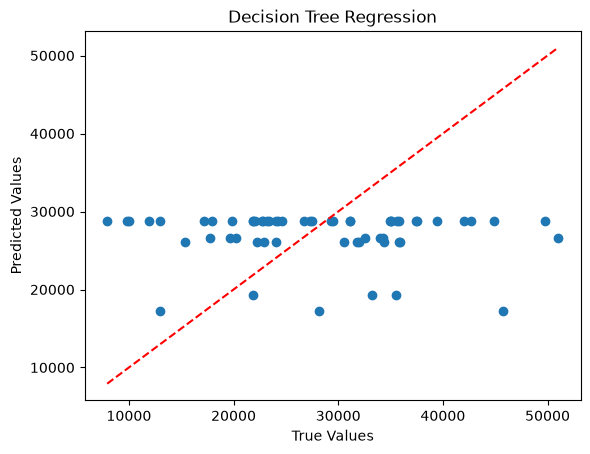

In [21]:
plt.figure()
plt.scatter(y_test, y_pred)
plt.xlabel('True Values')
plt.ylabel('Predicted Values')
plt.title('Decision Tree Regression')
high = max(y_test.max(), y_pred.max())
low = min(y_test.min(), y_pred.min())
plt.plot([low, high], [low, high], 'r--')
plt.show()